# Exercise8.02: GeoJSON choropleth and tooltip

LU MENGJIE - MC643920

CARTO now requires an API key. With user approval, Esri public light/dark gray tiles replace CARTO, while the custom HOT provider is retained. The bundled official Geoplotlib source has Python 3 / NumPy / SciPy compatibility fixes; it is not a replacement plotting library.

## Exercise8.02 - 01. Inspect fourth feature without changing source geometry

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../../Support').resolve()))
import course_maps
import geoplotlib
import pandas as pd
import numpy as np
from geoplotlib.utils import DataAccessObject, BoundingBox, read_csv
from IPython.display import display
DATA = Path('../../Datasets')
print('LU MENGJIE | MC643920 | Suggested Exercise 08')
print('Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.')
import json, copy
from geoplotlib.colors import ColorMap
with open(DATA/'us_states.json',encoding='utf8') as f: dataset=json.load(f)
fourth_state=copy.deepcopy(dataset['features'][3])
fourth_state['geometry']['coordinates']=fourth_state['geometry']['coordinates'][0][0]
print(json.dumps(fourth_state,indent=2))
states=[f['properties']['NAME'] for f in dataset['features']]
print('Number of geographic features:',len(states))
print(states)

LU MENGJIE | MC643920 | Suggested Exercise 08
Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.
{
  "type": "Feature",
  "properties": {
    "GEO_ID": "0400000US05",
    "STATE": "05",
    "NAME": "Arkansas",
    "LSAD": "",
    "CENSUSAREA": 52035.477
  },
  "geometry": {
    "type": "Polygon",
    "coordinates": [
      -94.042964,
      33.019219
    ]
  }
}
Number of geographic features: 52
['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 

## Exercise8.02 - 02. State outlines

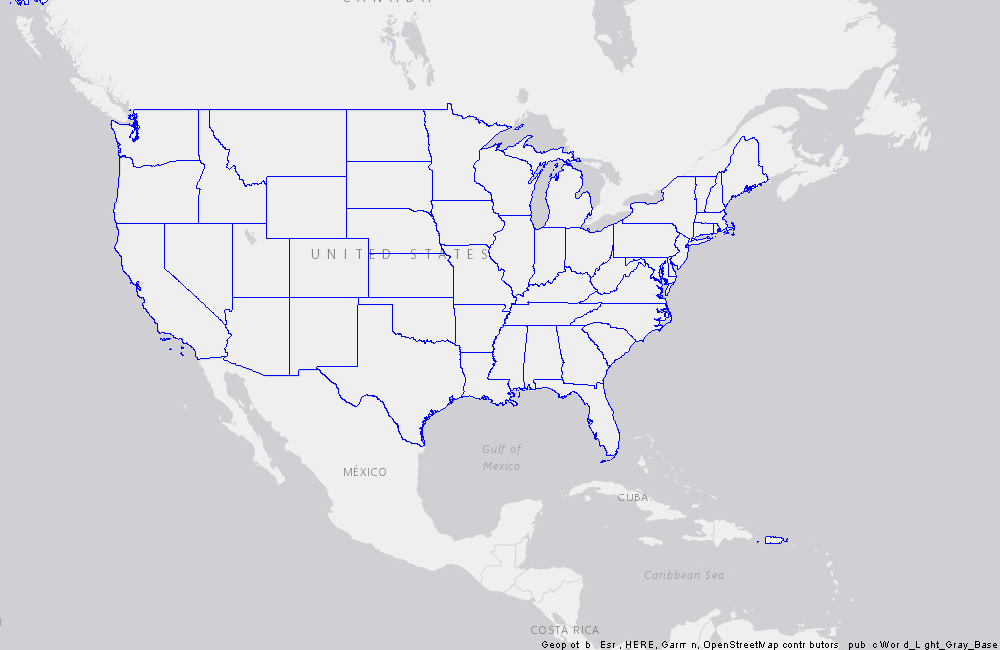

In [2]:
geoplotlib.geojson(str(DATA/'us_states.json'))
geoplotlib.set_bbox(BoundingBox.USA)
course_maps.snapshot('us_outlines')

## Exercise8.02 - 03. Ten-level Reds choropleth and black boundaries

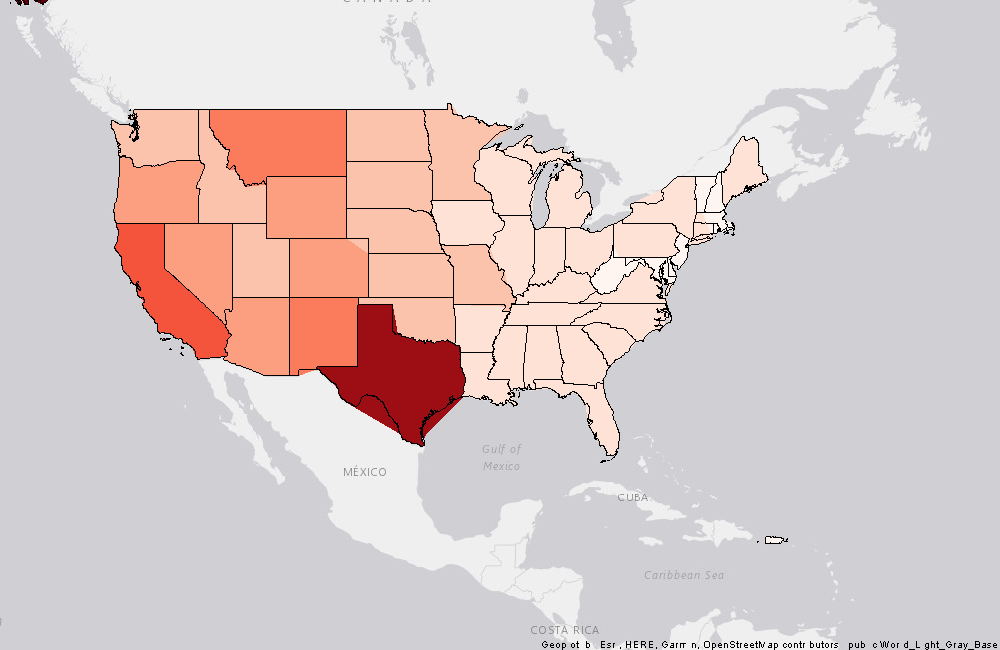

In [3]:
cmap=ColorMap('Reds',alpha=255,levels=10)
def get_color(properties):
    return cmap.to_color(properties['CENSUSAREA'],maxvalue=300000,scale='lin')
geoplotlib.geojson(str(DATA/'us_states.json'),fill=True,color=get_color)
geoplotlib.geojson(str(DATA/'us_states.json'),fill=False,color=[0,0,0,255])
geoplotlib.set_bbox(BoundingBox.USA)
course_maps.snapshot('us_choropleth')

## Exercise8.02 - 04. Hover tooltip

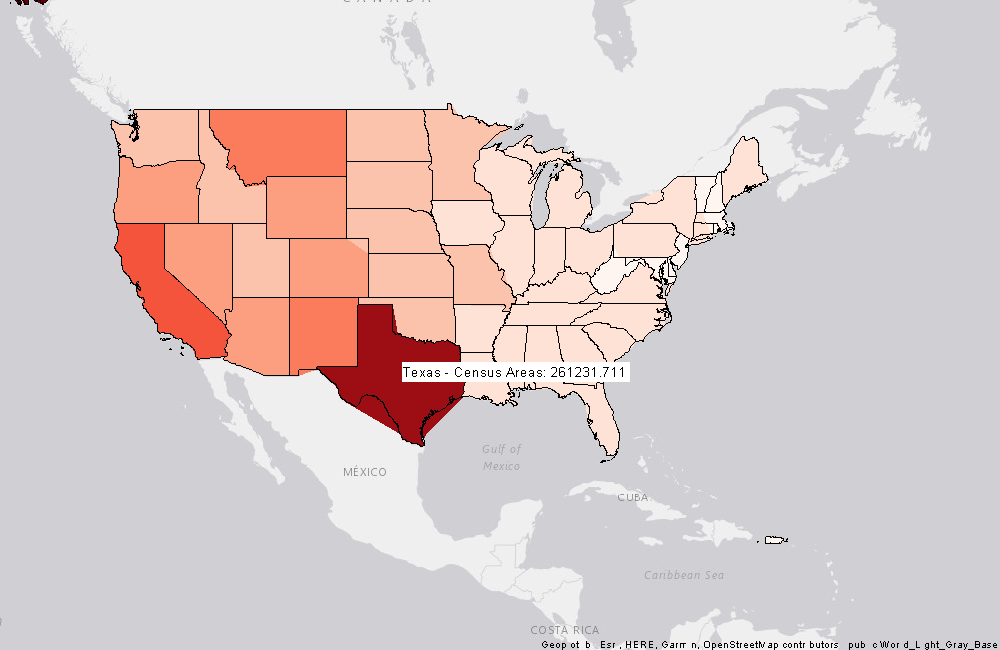

In [4]:
geoplotlib.geojson(str(DATA/'us_states.json'),fill=True,color=get_color,
    f_tooltip=lambda properties: properties['NAME']+' - Census Areas: '+str(properties['CENSUSAREA']))
geoplotlib.geojson(str(DATA/'us_states.json'),fill=False,color=[0,0,0,255])
geoplotlib.set_bbox(BoundingBox.USA)
course_maps.snapshot('us_tooltip',hover=(-99,31))